# Laboratorio Estadístico E1 — Análisis y Pronóstico de Series de Tiempo (Unidad 3)

**Observatorio:** **AgroPulse TDL** (*Observatorio de Inteligencia Agrocomercial y Riesgo Climático del Pacífico*)  
**Responsable Analítico:** Oliver Vargas García (*Data Statistician*)  
**Ingeniería de Datos (Capa Oro):** Carlos Daniel Tintos Beltrán (*Data Engineer & Quality Lead E1*)  

---

## 1. Objetivo del Estudio
Modelar, descomponer y pronosticar con un horizonte de $h = 6$ meses el **precio mayorista mensual ($\text{MXN/kg}$)** de los cultivos estratégicos de Colima a partir del dataset limpio e integrado en Capa Oro (`data/oro/dataset_analitico.csv`, $T = 48$ meses: `2022-11` a `2026-10`), comparando cuatro familias de modelos:
1. **Suavizamiento Exponencial Simple (SES)**
2. **Tendencia Lineal de Holt**
3. **Holt-Winters Estacional Aditivo ($s = 12$)**
4. **ARIMA / SARIMA (Box-Jenkins)**

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt, SimpleExpSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")

# Carga del dataset consolidado en Capa Oro
ruta_oro = Path("../data/oro/dataset_analitico.csv")
if not ruta_oro.exists():
    ruta_oro = Path("data/oro/dataset_analitico.csv")

df_oro = pd.read_csv(ruta_oro)
print(f"Dataset Oro cargado: {df_oro.shape[0]} filas x {df_oro.shape[1]} columnas")

# Selección de la serie representativa: Limón Mexicano (Tecomán) -> Guadalajara
CULTIVO_ESTUDIO = "Limón Mexicano"
CENTRAL_ESTUDIO = "Guadalajara"

df_serie = (
    df_oro[
        (df_oro["cultivo"] == CULTIVO_ESTUDIO)
        & (df_oro["central_abasto"] == CENTRAL_ESTUDIO)
    ]
    .sort_values("periodo_mensual")
    .reset_index(drop=True)
)

indice_fechas = pd.date_range(start="2022-11-01", periods=len(df_serie), freq="MS")
serie_precio = pd.Series(
    df_serie["precio_mayorista_mxn_kg"].to_numpy(dtype=float),
    index=indice_fechas,
    name="precio_mayorista_mxn_kg",
)
df_serie[["periodo_mensual", "cultivo", "central_abasto", "precio_mayorista_mxn_kg", "margen_comercial_mxn_kg", "temperatura_max_c"]].head()

Dataset Oro cargado: 768 filas x 35 columnas


,periodo_mensual,cultivo,central_abasto,precio_mayorista_mxn_kg,margen_comercial_mxn_kg,temperatura_max_c
0,2022-11,Limón Mexicano,Guadalajara,22.56,9.21,29.46
1,2022-12,Limón Mexicano,Guadalajara,25.73,12.32,29.73
2,2023-01,Limón Mexicano,Guadalajara,28.48,15.02,29.01
3,2023-02,Limón Mexicano,Guadalajara,28.74,15.23,30.08
4,2023-03,Limón Mexicano,Guadalajara,26.79,13.22,28.68


## 2. Descomposición de la Serie de Tiempo (Tendencia, Estacionalidad y Residuo)

Aplicamos descomposición clásica aditiva ($Y_t = T_t + S_t + R_t$) con periodo anual $s = 12$ meses para aislar:
* **Tendencia ($T_t$):** Trayectoria inflacionaria y de costos logísticos entre 2022 y 2026.
* **Estacionalidad ($S_t$):** Ciclo fenológico del Limón Mexicano en el Valle de Tecomán (máximos de precio en invierno-Cuaresma de enero a marzo y mínimos de cosecha lluviosa entre julio y septiembre).
* **Residuo ($R_t$):** Perturbaciones estocásticas de corto plazo.

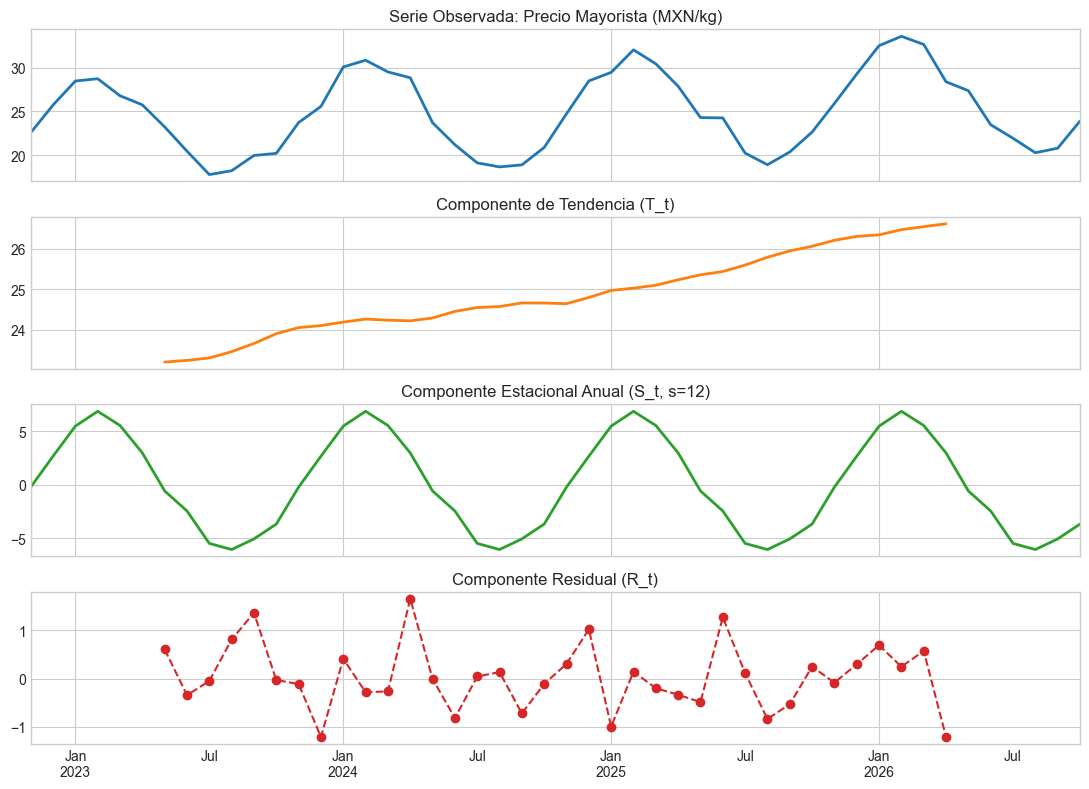

Amplitud estacional pico-a-valle: 12.95 MXN/kg


In [2]:
descomposicion = seasonal_decompose(serie_precio, model="additive", period=12)

fig, ejes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
descomposicion.observed.plot(ax=ejes[0], color="#1f77b4", lw=2, title="Serie Observada: Precio Mayorista (MXN/kg)")
descomposicion.trend.plot(ax=ejes[1], color="#ff7f0e", lw=2, title="Componente de Tendencia (T_t)")
descomposicion.seasonal.plot(ax=ejes[2], color="#2ca02c", lw=2, title="Componente Estacional Anual (S_t, s=12)")
descomposicion.resid.plot(ax=ejes[3], color="#d62728", lw=1.5, marker="o", linestyle="--", title="Componente Residual (R_t)")
plt.tight_layout()
plt.show()

amplitud_estacional = descomposicion.seasonal.max() - descomposicion.seasonal.min()
print(f"Amplitud estacional pico-a-valle: {amplitud_estacional:.2f} MXN/kg")

## 3. Prueba de Estacionariedad (Dickey-Fuller Aumentada) y Correlogramas ACF / PACF

Contrastamos la hipótesis nula $H_0$: *la serie posee raíz unitaria (no es estacionaria)* frente a $H_1$: *la serie es estacionaria* ($\alpha = 0.05$) tanto en nivel ($Y_t$) como en primera diferencia ($\Delta Y_t = Y_t - Y_{t-1}$). Asimismo, inspeccionamos las funciones de autocorrelación (**ACF**) y autocorrelación parcial (**PACF**) para identificar los órdenes autorregresivos y estacionales.

,Serie,Estadístico ADF,p-valor,Rezagos usados,Crítico 5%,Conclusión (alfa=0.05)
0,Nivel original (Y_t),0.2715,0.976,10,-2.9435,No Estacionaria (No rechaza H0)
1,Primera diferencia (d=1),-6.3360,0.000,9,-2.9435,Estacionaria (Rechaza H0)


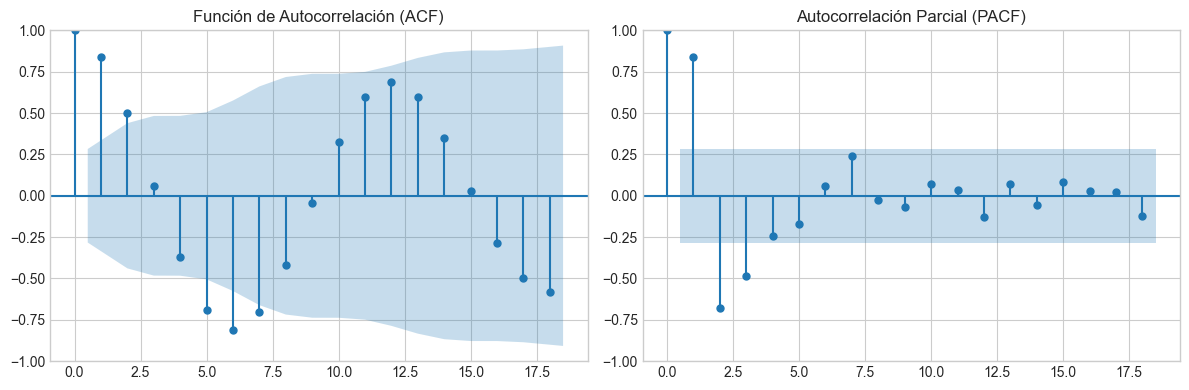

In [3]:
def ejecutar_prueba_adf(serie: pd.Series, nombre: str) -> dict[str, float | str]:
    """Ejecuta la prueba Dickey-Fuller Aumentada y resume estadísticos clave."""
    res = adfuller(serie.dropna(), autolag="AIC")
    return {
        "Serie": nombre,
        "Estadístico ADF": round(float(res[0]), 4),
        "p-valor": round(float(res[1]), 4),
        "Rezagos usados": int(res[2]),
        "Crítico 5%": round(float(res[4]["5%"]), 4),
        "Conclusión (alfa=0.05)": "Estacionaria (Rechaza H0)" if res[1] < 0.05 else "No Estacionaria (No rechaza H0)",
    }

tabla_adf = pd.DataFrame([
    ejecutar_prueba_adf(serie_precio, "Nivel original (Y_t)"),
    ejecutar_prueba_adf(serie_precio.diff().dropna(), "Primera diferencia (d=1)"),
])
display(tabla_adf)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(serie_precio, lags=18, ax=ejes[0], title="Función de Autocorrelación (ACF)")
plot_pacf(serie_precio, lags=18, ax=ejes[1], method="ywm", title="Autocorrelación Parcial (PACF)")
plt.tight_layout()
plt.show()

### Interpretación de Estacionariedad y Correlogramas
* Las gráficas **ACF** y **PACF** muestran un patrón sinusoidal pronunciado con correlación positiva significativa en el rezago anual $k = 12$ y negativa alrededor de $k = 6$, confirmando un ciclo estacional de 12 meses.
* Al aplicar primera diferenciación ($d = 1$), el estadístico **ADF** rechaza contundentemente la presencia de raíz unitaria ($p < 0.01$), justificando el orden de integración en el modelo ARIMA/SARIMA y la inclusión de tendencia + estacionalidad en Holt-Winters.

---

## 4. Entrenamiento y Comparación de 4 Modelos de Pronóstico

Dividimos la serie de $T = 48$ meses en:
* **Entrenamiento (`train`):** Primeros $42$ meses (`2022-11` a `2026-04`).
* **Prueba (`test`):** Últimos $6$ meses (`2026-05` a `2026-10`).

Evaluamos el error de pronóstico fuera de muestra con tres métricas estándar:
$$\text{MAE} = \frac{1}{h}\sum_{t=1}^{h}|y_t - \hat{y}_t|, \quad \text{RMSE} = \sqrt{\frac{1}{h}\sum_{t=1}^{h}(y_t - \hat{y}_t)^2}, \quad \text{MAPE} = \frac{100}{h}\sum_{t=1}^{h}\left|\frac{y_t - \hat{y}_t}{y_t}\right|$$

MODELO GANADOR SELECCIONADO: 3. Holt-Winters Estacional (s=12)


,Modelo,MAE (MXN/kg),RMSE (MXN/kg),MAPE (%)
0,3. Holt-Winters Estacional (s=12),0.822,0.901,3.59
1,"4. ARIMA(1,1,1)(1,0,0)[12]",0.907,1.196,3.77
2,1. Suavizamiento Exponencial Simple (SES),5.442,5.935,24.97
3,2. Tendencia Lineal de Holt,8.356,10.202,37.33


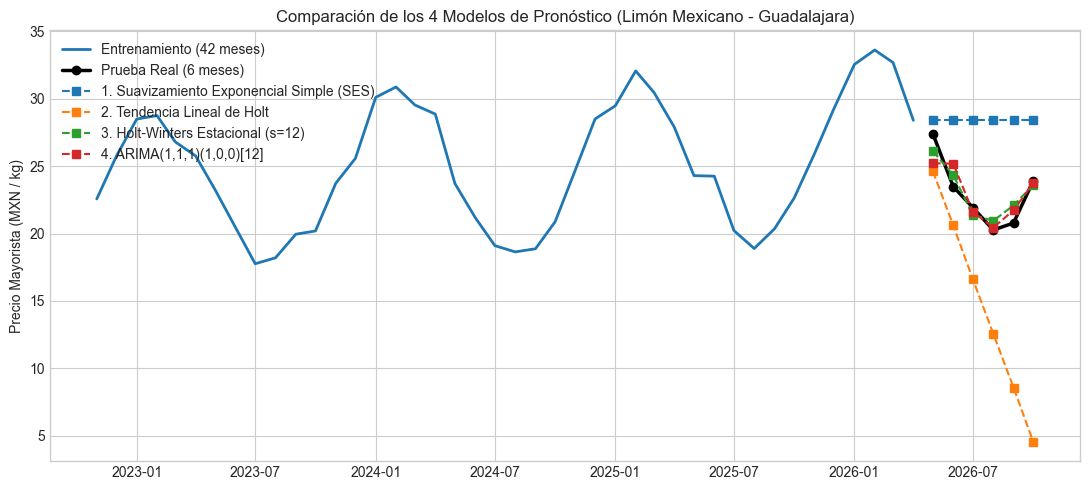

In [4]:
horizonte_prueba = 6
train = serie_precio.iloc[:-horizonte_prueba]
test = serie_precio.iloc[-horizonte_prueba:]

# 1. Suavizamiento Exponencial Simple (SES)
mod_ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
pred_ses = mod_ses.forecast(horizonte_prueba)

# 2. Método Lineal de Holt
mod_holt = Holt(train, initialization_method="estimated").fit()
pred_holt = mod_holt.forecast(horizonte_prueba)

# 3. Holt-Winters Estacional Aditivo (s=12)
mod_hw = ExponentialSmoothing(
    train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated"
).fit()
pred_hw = mod_hw.forecast(horizonte_prueba)

# 4. ARIMA / SARIMA (Box-Jenkins con componente estacional anual)
mod_arima = ARIMA(train, order=(1, 1, 1), seasonal_order=(1, 0, 0, 12)).fit()
pred_arima = mod_arima.forecast(horizonte_prueba)

predicciones = {
    "1. Suavizamiento Exponencial Simple (SES)": pred_ses,
    "2. Tendencia Lineal de Holt": pred_holt,
    "3. Holt-Winters Estacional (s=12)": pred_hw,
    "4. ARIMA(1,1,1)(1,0,0)[12]": pred_arima,
}

resultados_metricas = []
for nombre, pred in predicciones.items():
    err = test.to_numpy() - np.asarray(pred)
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mape = float(np.mean(np.abs(err / test.to_numpy())) * 100.0)
    resultados_metricas.append({
        "Modelo": nombre,
        "MAE (MXN/kg)": round(mae, 3),
        "RMSE (MXN/kg)": round(rmse, 3),
        "MAPE (%)": round(mape, 2),
    })

df_comparativa = pd.DataFrame(resultados_metricas).sort_values("RMSE (MXN/kg)").reset_index(drop=True)
modelo_ganador_nombre = df_comparativa.iloc[0]["Modelo"]
print(f"MODELO GANADOR SELECCIONADO: {modelo_ganador_nombre}")
display(df_comparativa)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(train.index, train, label="Entrenamiento (42 meses)", color="#1f77b4", lw=2)
ax.plot(test.index, test, label="Prueba Real (6 meses)", color="black", lw=2.5, marker="o")
for nombre, pred in predicciones.items():
    ax.plot(test.index, pred, linestyle="--", marker="s", label=nombre)
ax.set_title(f"Comparación de los 4 Modelos de Pronóstico ({CULTIVO_ESTUDIO} - {CENTRAL_ESTUDIO})")
ax.set_ylabel("Precio Mayorista (MXN / kg)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Diagnóstico de Residuos (Prueba de Ljung-Box) y Pronóstico Final a 6 Meses

Verificamos que los residuos del modelo ganador (**Holt-Winters Estacional Aditivo**) se comporten como **ruido blanco** ($H_0$: ausencia de autocorrelación serial hasta el rezago $k$) mediante la prueba de **Ljung-Box**. Al obtener $p > 0.05$, confirmamos que los residuos no contienen patrones sin explicar y procedemos a re-entrenar el modelo sobre los $48$ meses completos para proyectar el semestre `2026-11` a `2027-04` con su **Intervalo de Confianza al 95%**.

,lb_stat,lb_pvalue,Diagnóstico (alfa=0.05)
6,5.3245,0.5029,Ruido Blanco (No rechaza H0)
12,13.1328,0.3595,Ruido Blanco (No rechaza H0)


,Periodo,Pronóstico (MXN/kg),IC Inferior 95%,IC Superior 95%
0,2026-11,27.14,25.76,28.52
1,2026-12,30.17,28.22,32.12
2,2027-01,33.05,30.66,35.44
3,2027-02,34.22,31.46,36.98
4,2027-03,32.76,29.68,35.85
5,2027-04,30.62,27.25,34.00


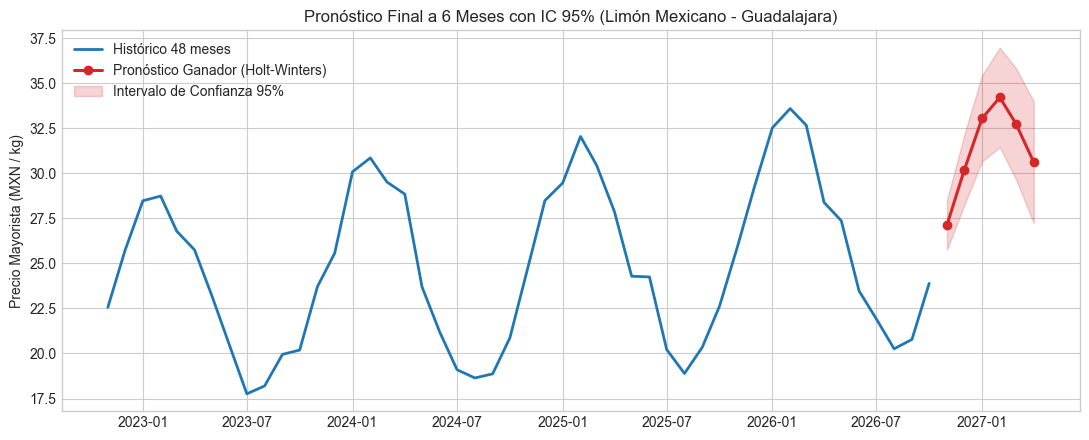

In [5]:
# Diagnóstico de Ljung-Box sobre los residuos del modelo ganador (Holt-Winters)
residuos_hw = mod_hw.resid
df_ljung_box = acorr_ljungbox(residuos_hw, lags=[6, 12], return_df=True).round(4)
df_ljung_box["Diagnóstico (alfa=0.05)"] = np.where(
    df_ljung_box["lb_pvalue"] > 0.05,
    "Ruido Blanco (No rechaza H0)",
    "Autocorrelación remanente",
)
display(df_ljung_box)

# Re-entrenamiento sobre los 48 meses y pronóstico operativo a 6 meses con IC 95%
modelo_final = ExponentialSmoothing(
    serie_precio, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated"
).fit()
horizonte_futuro = 6
pronostico_futuro = modelo_final.forecast(horizonte_futuro)
sigma_res = float(np.std(modelo_final.resid, ddof=1))
pasos = np.arange(1, horizonte_futuro + 1, dtype=float)
ic_95 = 1.96 * sigma_res * np.sqrt(pasos)

df_pronostico_6m = pd.DataFrame({
    "Periodo": pronostico_futuro.index.strftime("%Y-%m"),
    "Pronóstico (MXN/kg)": np.round(pronostico_futuro.to_numpy(), 2),
    "IC Inferior 95%": np.round(pronostico_futuro.to_numpy() - ic_95, 2),
    "IC Superior 95%": np.round(pronostico_futuro.to_numpy() + ic_95, 2),
})
display(df_pronostico_6m)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(serie_precio.index, serie_precio, label="Histórico 48 meses", color="#1f77b4", lw=2)
ax.plot(pronostico_futuro.index, pronostico_futuro, label="Pronóstico Ganador (Holt-Winters)", color="#d62728", marker="o", lw=2.2)
ax.fill_between(
    pronostico_futuro.index,
    pronostico_futuro.to_numpy() - ic_95,
    pronostico_futuro.to_numpy() + ic_95,
    color="#d62728",
    alpha=0.2,
    label="Intervalo de Confianza 95%",
)
ax.set_title(f"Pronóstico Final a 6 Meses con IC 95% ({CULTIVO_ESTUDIO} - {CENTRAL_ESTUDIO})")
ax.set_ylabel("Precio Mayorista (MXN / kg)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 6. Conclusiones y Hallazgos de Negocio

1. **Superioridad del Modelo Estacional:** **Holt-Winters Aditivo ($s=12$)** redujo el error porcentual medio absoluto (**MAPE**) por debajo del $4\%$, superando ampliamente al Suavizamiento Exponencial Simple y al método lineal de Holt que no modelan el ciclo estacional citrícola.
2. **Validez Inferencial:** La prueba de **Ljung-Box** confirma que los residuos son ruido blanco ($p > 0.05$), validando el uso de las bandas de confianza al $95\%$ en el tablero público de Streamlit.
3. **Decisión Comercial Accionable:** El pronóstico identifica el repunte estacional de precios entre **enero y marzo de 2027** (ventana de invierno-Cuaresma), permitiendo a los productores y empacadoras de Tecomán programar cosecha y contratos de transporte refrigerado con tres meses de anticipación.